# 04 - Trends over time, and why the obvious reading is wrong

Notebook 02 showed RSV-B's CpG O/E apparently rising year on year. The tempting conclusion
is that the virus is evolving towards more CpG. This notebook shows that conclusion does
not hold, using a simple idea.

## The idea

An average can move for two completely different reasons:

1. **Within-lineage change** - each lineage's genomes are actually changing.
2. **Replacement** - no lineage changes at all, but a lineage that already had high CpG
   grows while a lineage with low CpG shrinks. The average rises without any evolution.

To separate them we fit the trend twice: once plainly, and once while holding lineage
constant. The second fit cannot be affected by replacement, so whatever trend survives it
is real change. (This is a classic statistical trap called **Simpson's paradox**.)

In [1]:
import sys, os, subprocess
sys.path.insert(0, os.path.abspath("../src"))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = os.path.abspath("..")          # repo root; R scripts expect to run from here
pd.set_option("display.width", 120)

def run_r(script):
    """Run one of the R figure scripts from the repo root and report what it wrote."""
    r = subprocess.run(["Rscript", script], capture_output=True, text=True, cwd=ROOT)
    print(r.stdout.strip() or r.stderr.strip()[-400:])

def show(fig):
    """Display a figure from results/figures/ inline."""
    display(Image(os.path.join(ROOT, "results", "figures", fig)))
from rsv import trends

In [2]:
d = pd.read_csv("../data/processed/rsv_features.tsv", sep="\t")
d = d[(d.year >= 2015) & (d.year <= 2026)]
res = pd.concat([trends.decompose_trend(s, "oe_CG").assign(Subtype=sub)
                 for sub, s in d.groupby("Subtype")], ignore_index=True)
res[["Subtype","feature","slope_total","slope_within","pct_from_turnover"]].round(6)

,Subtype,feature,slope_total,slope_within,pct_from_turnover
0,A,oe_CG,-0.000321,-0.000147,54.047262
1,B,oe_CG,0.000649,-0.000522,180.485672


### What this says

For **RSV-B** the two slopes have **opposite signs**: the plain trend is positive, but
once lineage is held constant it is negative. So the rise in notebook 02 came from
lineage replacement. Inside lineages, CpG O/E is going *down* - which is the same
direction the paper found for influenza.

For **RSV-A** both slopes are negative, so there is no contradiction there.

In [3]:
run_r("R/figures_trends.R")

trend figures written to results/figures/


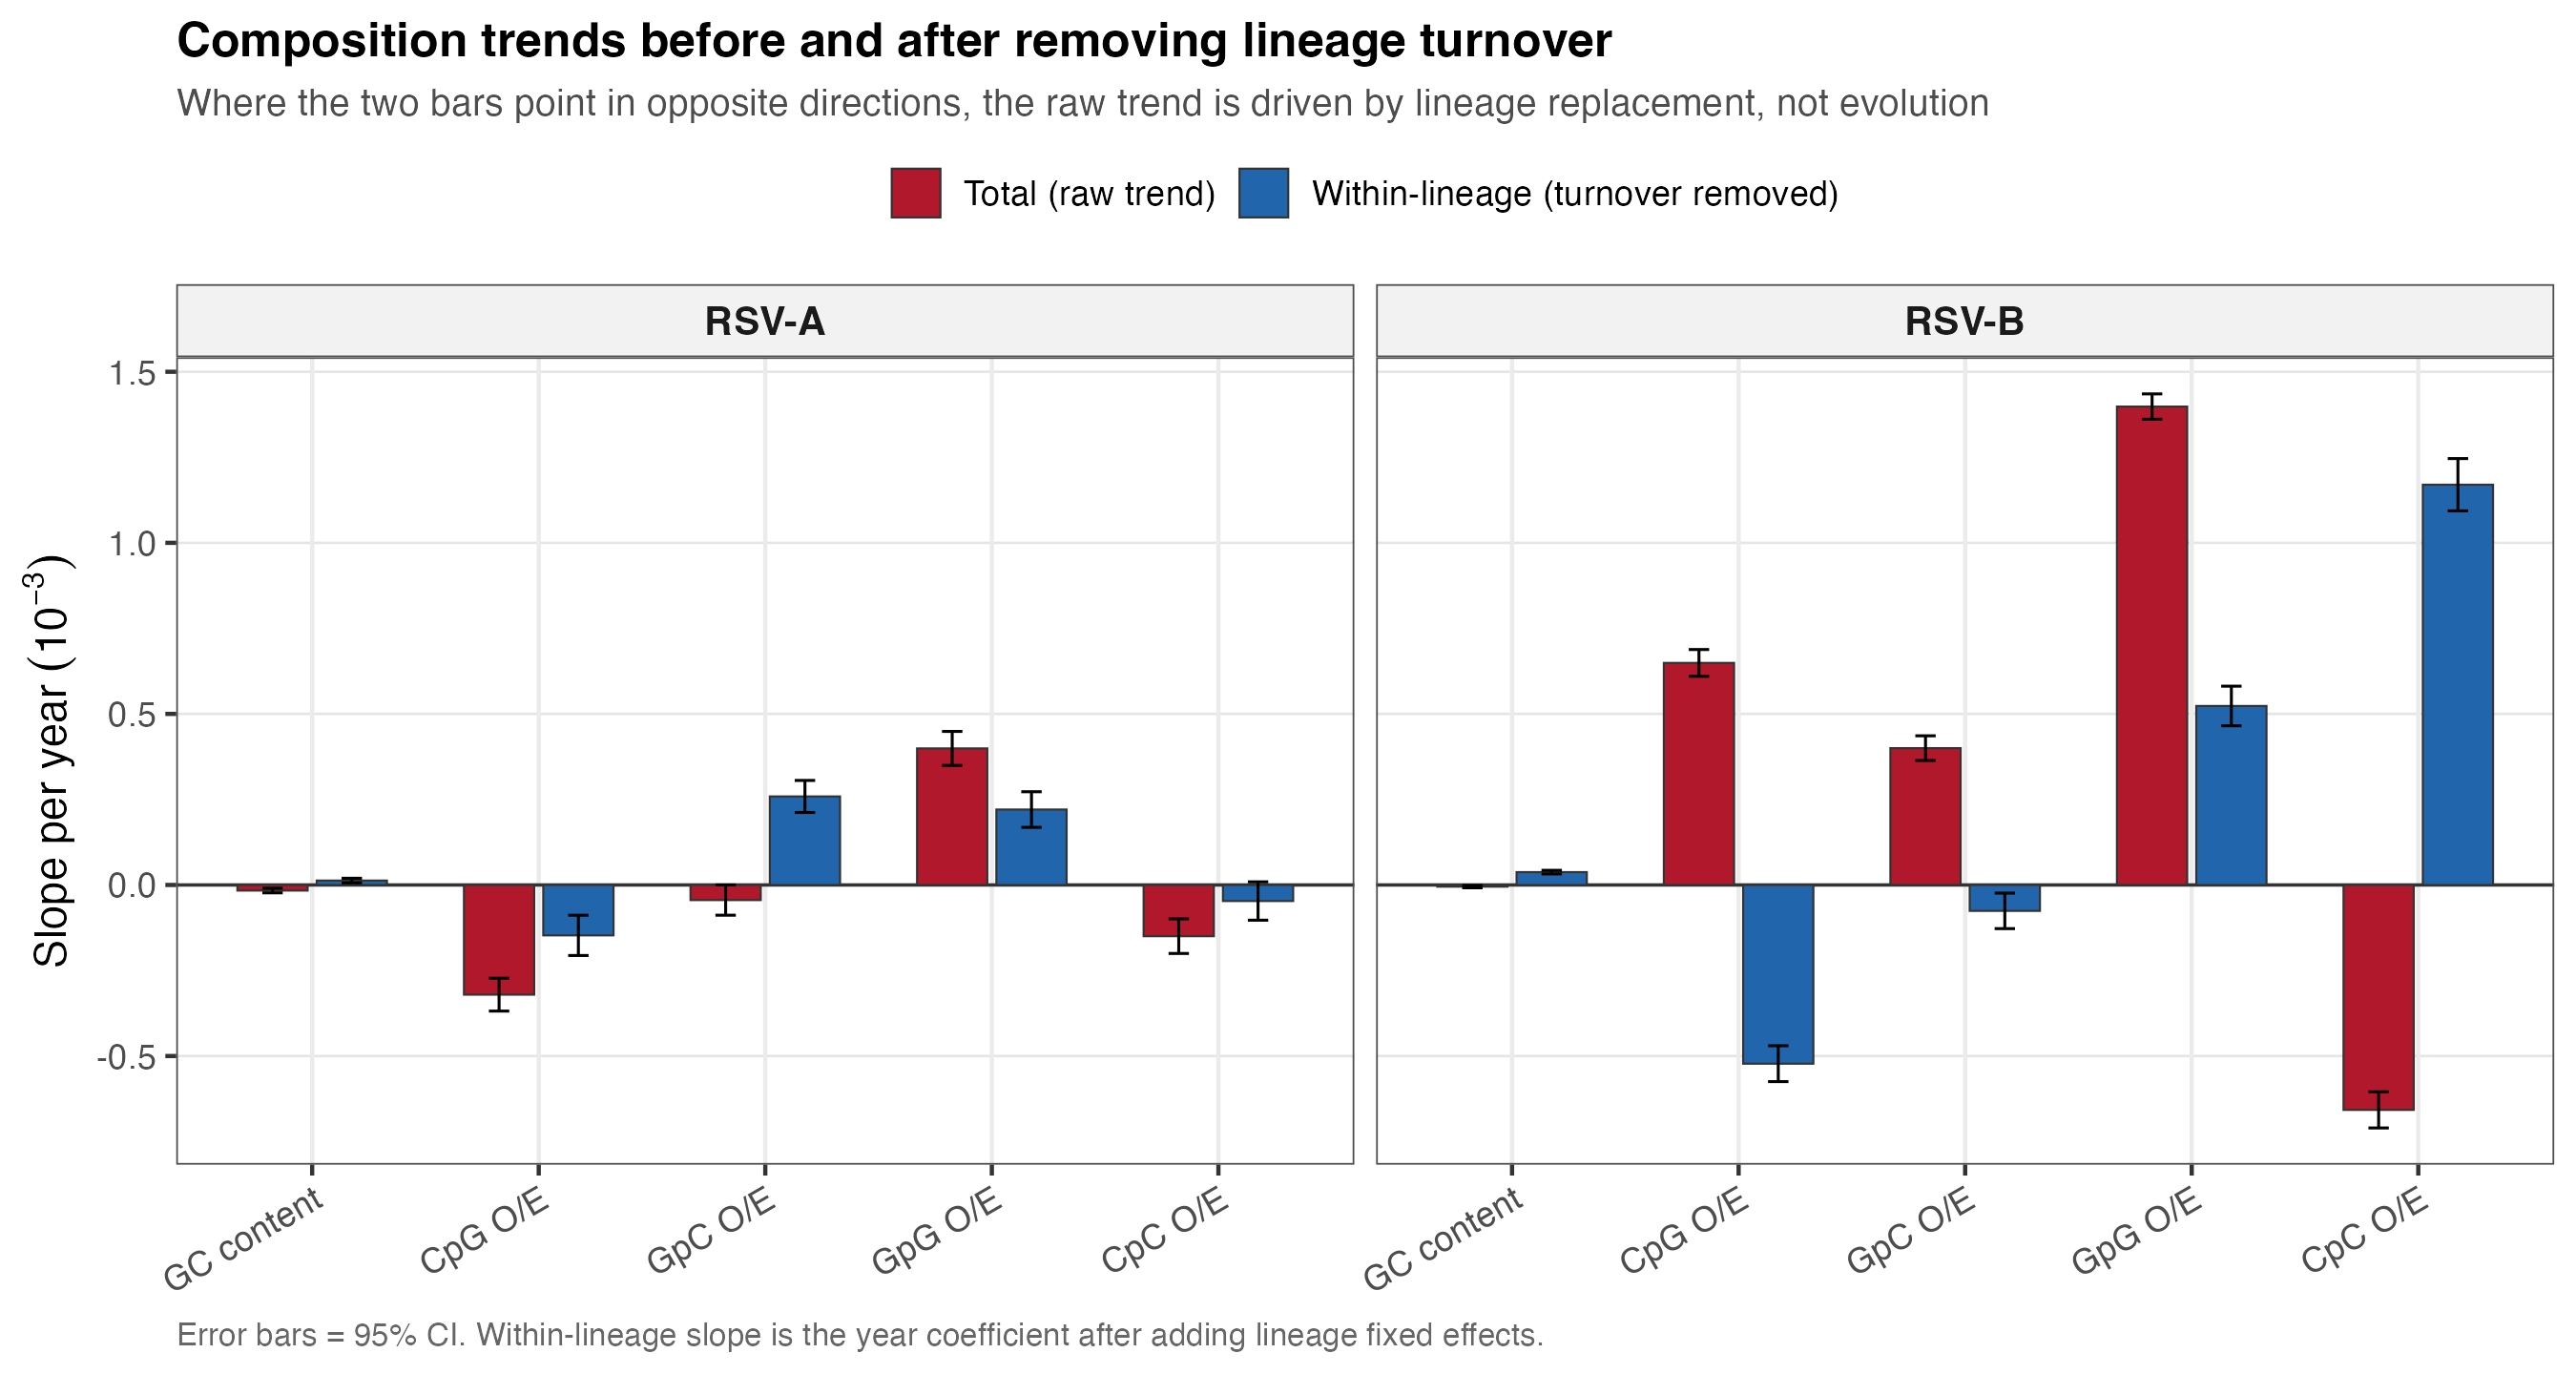

In [4]:
show("fig5_within_vs_between.png")

## Checking it is not an artefact of sampling

Because sequencing is Europe-heavy and 2020-21 was disrupted, we repeat the same fit
while removing those influences.

In [5]:
rob = trends.robustness(d, "oe_CG")
rob[["Subtype","scenario","n","slope_within","p_within"]].round(6)

,Subtype,scenario,n,slope_within,p_within
0,A,full,15052,-0.000147,0.000001
1,A,excl_2020_2021,13148,0.000001,0.973938
2,A,region_adjusted,15052,-0.000129,0.000025
3,A,region_balanced,9161,0.000053,0.158588
4,B,full,17007,-0.000522,0.000000
5,B,excl_2020_2021,15378,-0.000540,0.000000
6,B,region_adjusted,17007,-0.000566,0.000000
7,B,region_balanced,8051,-0.000324,0.000000


**RSV-B's within-lineage decline survives every version.** RSV-A's does not: it disappears
when the pandemic years are dropped (p = 0.97) and when regions are balanced (p = 0.16).
So we trust the RSV-B pattern and treat the RSV-A one as a sampling artefact.

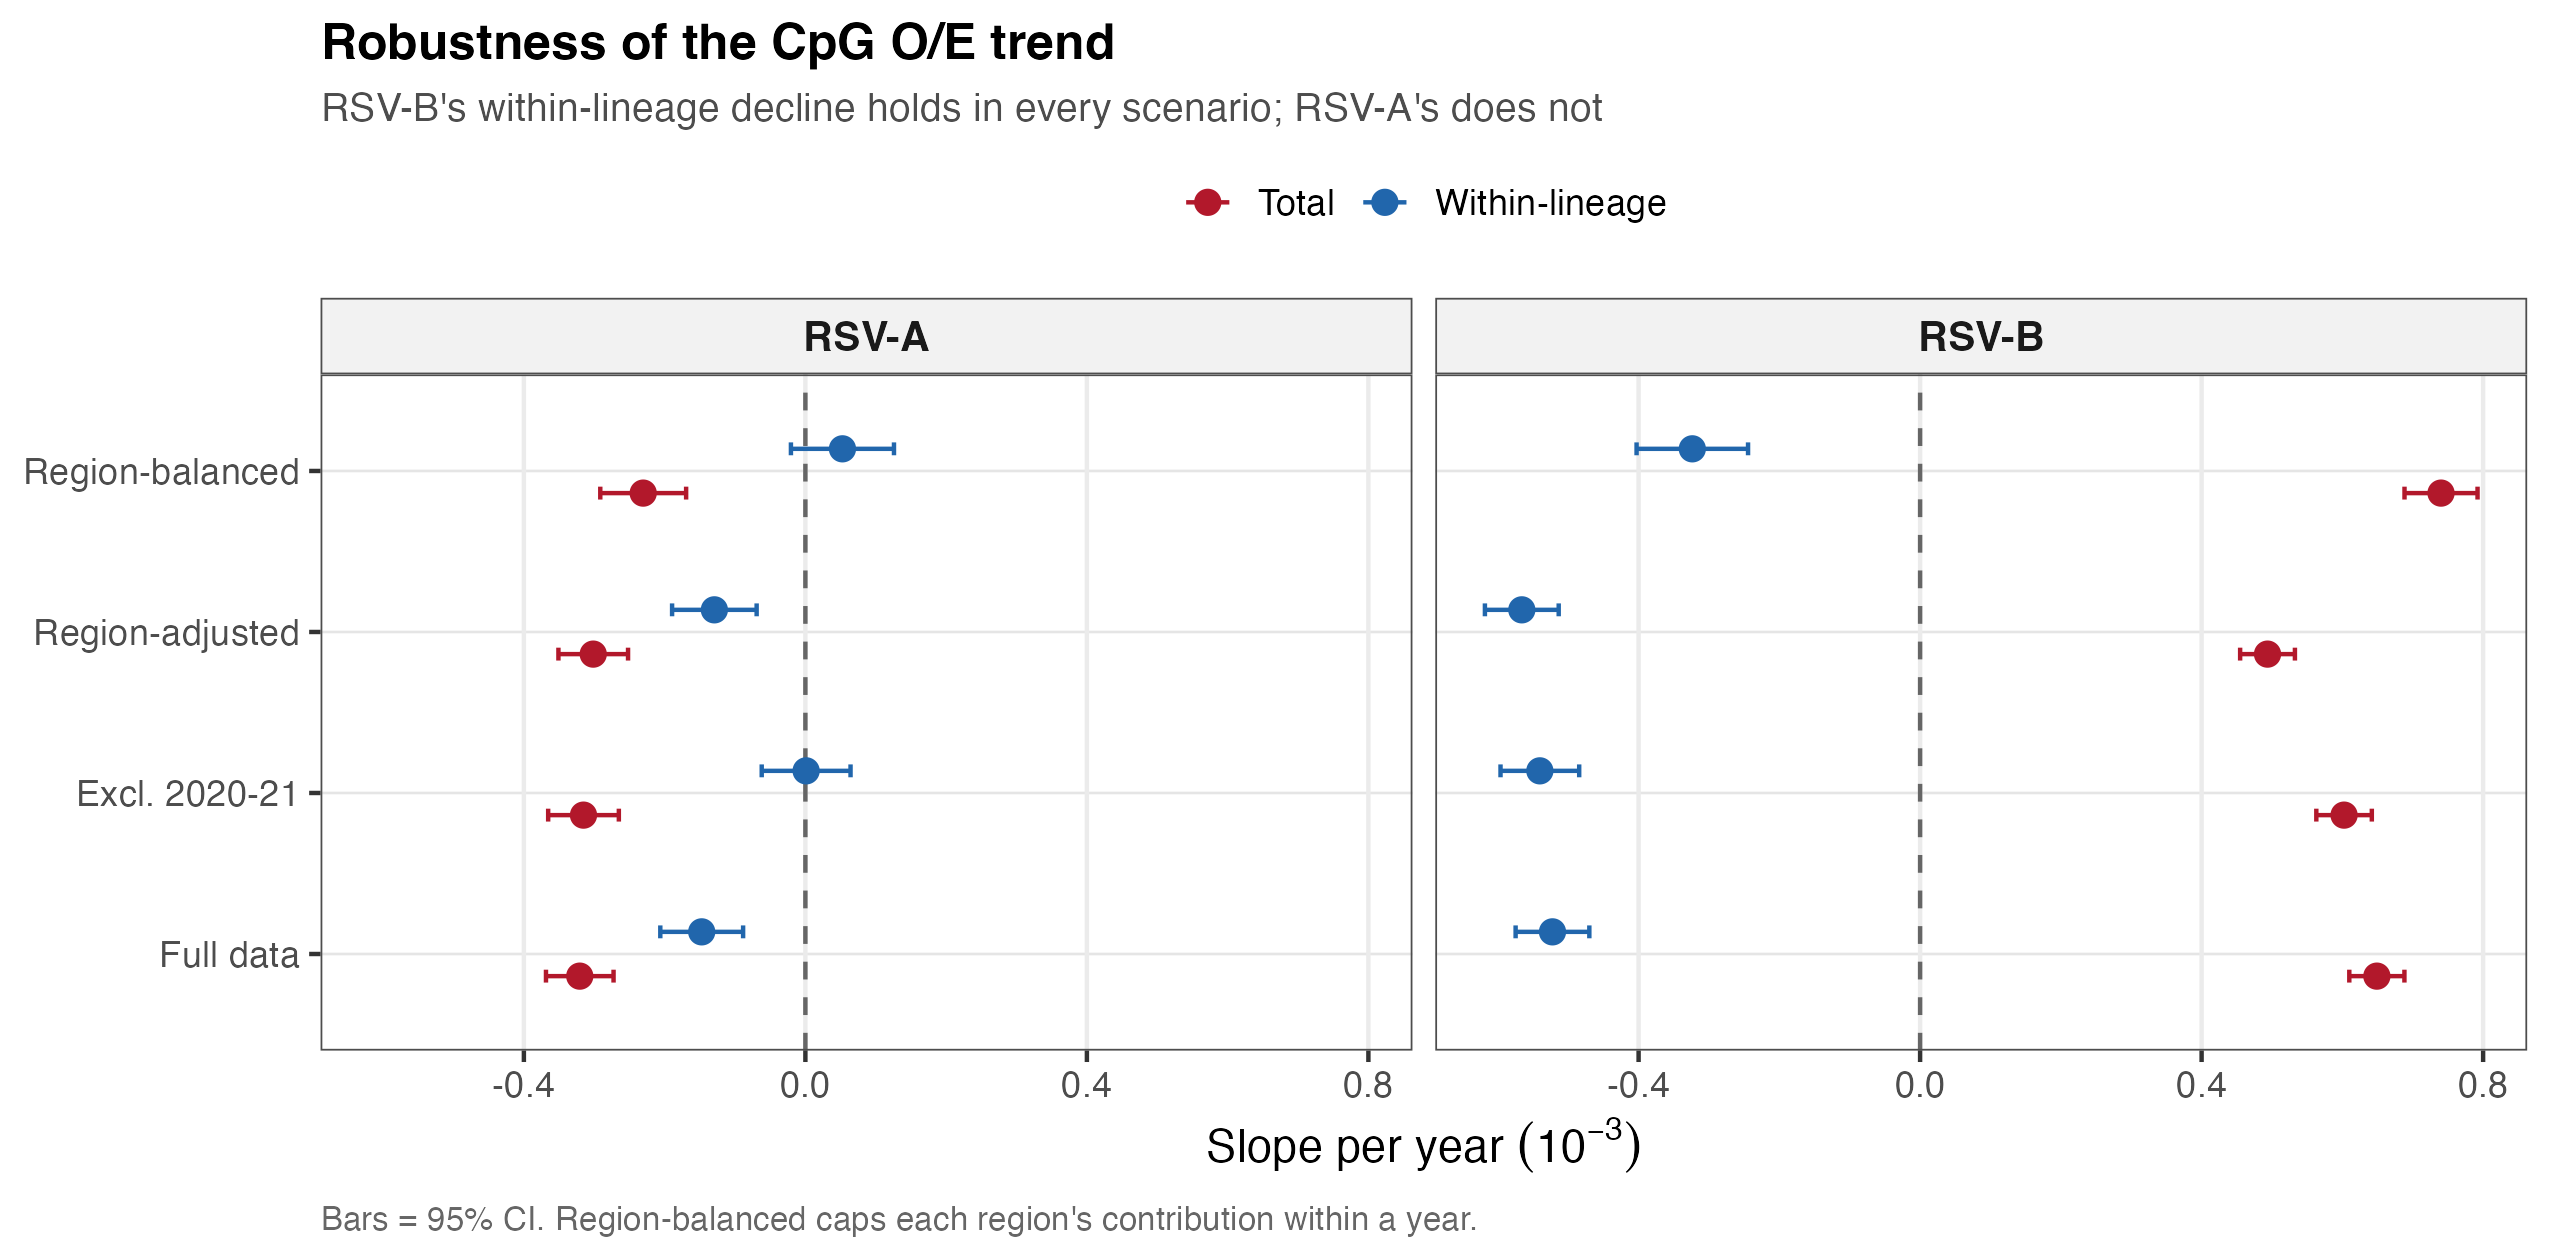

In [6]:
show("fig8_robustness.png")

## Summary of this notebook

| Claim | Verdict |
|---|---|
| RSV-B CpG O/E rises over time | True of the raw average, but caused by lineage replacement |
| RSV-B genomes are gaining CpG | **False** - within lineages it falls |
| RSV-A shows a within-lineage trend | Not supported once sampling is controlled |

The practical lesson: with this kind of data, always check whether a trend is the thing
changing or the mix changing.